# 이커머스 데이터 분석 리포트: 단골 고객 찾기

이 노트북은 두 데이터로 분석한다.

| 데이터 | 역할 | 출처·라이선스 |
|---|---|---|
| 거래 데이터 `online_retail_II.csv` | 고객 구매 분석, RFM 세분화 | [UCI Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii), Chen, D. (2012), CC BY 4.0 |
| 상품 데이터 `products.csv` + 상품 이미지 | 멀티 모달(텍스트·범주·이미지) 피처 엔지니어링 | [Fashion Product Images (Small)](https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small), MIT. Hugging Face 미러 `ashraq/fashion-product-images-small`에서 2,000개 표본 |

두 데이터는 서로 다른 회사의 데이터라 상품이 연결되지 않는다. 그래서 **고객 거래 분석**과 **상품 멀티 모달 분석**을 두 흐름으로 나눠 진행한다.

분석 로직은 모두 `src/pipeline.py`의 `DataAnalyzer` 클래스에 있고, 이 노트북은 그 메서드를 호출하며 결과를 해석한다. 데이터 준비: `uv run python scripts/download_data.py`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from pipeline import DataAnalyzer
from plot_style import BLUE, GRAY, GREEN, ORANGE, RED, SEGMENT_COLORS, plain_log_ticks, save_figure, setup_style

np.random.seed(42)
setup_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

## 1. 데이터 로드와 기본 탐색

### 1-1. 거래 데이터

In [2]:
tx = DataAnalyzer(ROOT / "data" / "online_retail_II.csv")
tx.load_data(parse_dates=["InvoiceDate"],
             dtype={"Invoice": str, "StockCode": str, "Customer ID": "string"})
tx.df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  str           
 1   StockCode    1067371 non-null  str           
 2   Description  1062989 non-null  str           
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   string        
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(1), str(4), string(1)
memory usage: 65.1 MB


In [3]:
tx.df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom


In [4]:
tx.df.describe()

,Quantity,InvoiceDate,Price
count,"1,067,371.00",1067371,"1,067,371.00"
mean,9.94,2011-01-02 21:13:55.394029,4.65
min,"-80,995.00",2009-12-01 07:45:00,"-53,594.36"
25%,1.00,2010-07-09 09:46:00,1.25
50%,3.00,2010-12-07 15:28:00,2.10
75%,10.00,2011-07-22 10:23:00,4.15
max,"80,995.00",2011-12-09 12:50:00,"38,970.00"
std,172.71,NaN,123.55


In [5]:
d = tx.df
print(f"기간: {d['InvoiceDate'].min()} ~ {d['InvoiceDate'].max()}")
print(f"주문 수: {d['Invoice'].nunique():,}, 상품 코드 수: {d['StockCode'].nunique():,}, "
      f"고객 수: {d['Customer ID'].nunique():,}, 국가 수: {d['Country'].nunique()}")
print(f"취소 주문 행(Invoice가 C로 시작): {d['Invoice'].str.startswith('C').sum():,}")
print(f"수량 0 이하: {(d['Quantity'] <= 0).sum():,}, 단가 0 이하: {(d['Price'] <= 0).sum():,}")
print(f"영국 비중: {(d['Country'] == 'United Kingdom').mean() * 100:.1f}%")

기간: 2009-12-01 07:45:00 ~ 2011-12-09 12:50:00


주문 수: 53,628, 상품 코드 수: 5,305, 고객 수: 5,942, 국가 수: 43
취소 주문 행(Invoice가 C로 시작): 19,494
수량 0 이하: 22,950, 단가 0 이하: 6,207
영국 비중: 91.9%


**해석**

- 거래 데이터는 1,067,371행 × 8열이고, 2009-12-01부터 2011-12-09까지 약 2년 동안의 주문 53,628건이다. 고객 5,942명, 상품 코드 5,305개, 43개국이 있지만 **영국 비중이 91.9%**로 사실상 영국 쇼핑몰이다.
- `Quantity`의 최솟값 −80,995와 최댓값 80,995가 같은 크기다. 큰 주문이 들어왔다가 그대로 취소된 흔적이다. 취소 주문 행이 19,494개, 수량 0 이하 22,950개, 단가 0 이하 6,207개라서 **판매 분석 전에 이런 행을 걸러야 한다.**
- `Quantity` 평균 9.94가 중앙값 3의 3배가 넘는다. 소수의 대량 주문이 평균을 끌어올리는 **오른쪽으로 긴 분포**이므로, 대표값은 중앙값으로 보고 그래프는 로그 축으로 그린다.

### 1-2. 상품 데이터 (멀티 모달)

In [6]:
pr = DataAnalyzer(ROOT / "data" / "products.csv")
pr.load_data()
pr.df["image_path"] = [str(ROOT / p) for p in pr.df["image_path"]]
pr.df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  2000 non-null   int64  
 1   gender              2000 non-null   str    
 2   masterCategory      2000 non-null   str    
 3   subCategory         2000 non-null   str    
 4   articleType         2000 non-null   str    
 5   baseColour          2000 non-null   str    
 6   season              2000 non-null   str    
 7   year                2000 non-null   float64
 8   usage               2000 non-null   str    
 9   productDisplayName  2000 non-null   str    
 10  image_path          2000 non-null   str    
dtypes: float64(1), int64(1), str(9)
memory usage: 172.0 KB


In [7]:
pr.df.head()

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,image_path
0,35542,Girls,Footwear,Sandal,Sandals,Pink,Summer,"2,012.00",Casual,Enroute Kids Girls Pink Sandals,/Users/ashofrondol/Desktop/temp/codyssey_A1-1/...
1,26969,Women,Apparel,Topwear,Tops,White,Summer,"2,012.00",Casual,Jealous 21 Women Printed White & Blue Top,/Users/ashofrondol/Desktop/temp/codyssey_A1-1/...
2,51007,Women,Apparel,Innerwear,Bra,Black,Summer,"2,017.00",Casual,Enamor Black Full Figure Bra,/Users/ashofrondol/Desktop/temp/codyssey_A1-1/...
3,48916,Women,Accessories,Jewellery,Pendant,Silver,Summer,"2,013.00",Casual,Lucera Women Silver Pendant,/Users/ashofrondol/Desktop/temp/codyssey_A1-1/...
4,17612,Girls,Apparel,Topwear,Tshirts,Grey,Fall,"2,011.00",Casual,Doodle Cute Girls Grey Tshirt,/Users/ashofrondol/Desktop/temp/codyssey_A1-1/...


In [8]:
pr.df.describe(include="all").T[["count", "unique", "top", "freq", "mean", "min", "max"]]

,count,unique,top,freq,mean,min,max
id,"2,000.00",NaN,NaN,NaN,"29,701.46","1,164.00","59,979.00"
gender,2000,5,Men,984,NaN,NaN,NaN
masterCategory,2000,5,Apparel,1000,NaN,NaN,NaN
subCategory,2000,32,Topwear,715,NaN,NaN,NaN
articleType,2000,93,Tshirts,317,NaN,NaN,NaN
baseColour,2000,41,Black,435,NaN,NaN,NaN
season,2000,4,Summer,970,NaN,NaN,NaN
year,"2,000.00",NaN,NaN,NaN,"2,012.71","2,010.00","2,018.00"
usage,2000,6,Casual,1534,NaN,NaN,NaN
productDisplayName,2000,1904,Lucera Women Silver Earrings,5,NaN,NaN,NaN


In [9]:
types = pd.DataFrame({
    "데이터": ["거래", "거래", "거래", "거래", "상품", "상품", "상품", "상품"],
    "유형": ["수치형", "범주형", "날짜형", "텍스트", "수치형", "범주형", "텍스트", "이미지(배열)"],
    "컬럼": ["Quantity, Price", "Country, StockCode", "InvoiceDate", "Description",
             "year (+ 이미지 피처)", "gender, masterCategory, articleType, baseColour, season, usage",
             "productDisplayName", "image_path → (80, 60) 배열"],
})
types

,데이터,유형,컬럼
0,거래,수치형,"Quantity, Price"
1,거래,범주형,"Country, StockCode"
2,거래,날짜형,InvoiceDate
3,거래,텍스트,Description
4,상품,수치형,year (+ 이미지 피처)
5,상품,범주형,"gender, masterCategory, articleType, baseColou..."
6,상품,텍스트,productDisplayName
7,상품,이미지(배열),"image_path → (80, 60) 배열"


**해석**

- 상품 표본은 2,000개 × 11열(이미지 경로 포함)이고 수치형(`year`), 범주형 6개, 텍스트(`productDisplayName`), 이미지까지 **4가지 유형**이 모두 있다. 거래 데이터까지 합치면 날짜형도 있어 명세의 "3가지 이상"을 채운다.
- 카테고리가 고르지 않다. Apparel이 1,000개(50%)로 절반이고 Free Items는 4개뿐이다. 상품 종류(`articleType`)는 93종이며 Tshirts가 317개로 가장 많다.
- 그래서 이미지 피처를 비교할 때는 **카테고리별로 나눠 보아야** 표본이 많은 의류의 특성이 전체 결과를 덮지 않는다.

## 2. 결측치 처리

In [10]:
tx.missing_report()

,결측 개수,결측 비율(%)
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


In [11]:
pr.missing_report().T

,id,gender,masterCategory,subCategory,articleType,baseColour,season,year,usage,productDisplayName,image_path
결측 개수,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
결측 비율(%),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [12]:
# 같은 상품 코드(StockCode)는 같은 상품명을 가지므로, 코드별 최빈 상품명으로 채운다 (그룹별 대치)
missing_desc = tx.df["Description"].isna()
filled = tx.handle_missing_values("Description", strategy="group_mode", group_col="StockCode")
left = int(tx.df["Description"].isna().sum())
print(f"Description 결측 {missing_desc.sum():,}칸 중 {filled:,}칸을 같은 StockCode의 최빈 상품명으로 채움")
print(f"남은 {left:,}칸은 그 StockCode에 상품명이 한 번도 없어 'UNKNOWN'으로 채움")
tx.handle_missing_values("Description", strategy="constant", fill_value="UNKNOWN")
print("남은 결측 행의 단가 분포 (대부분 0원):")
print(tx.df.loc[missing_desc, "Price"].describe())

Description 결측 4,382칸 중 4,019칸을 같은 StockCode의 최빈 상품명으로 채움
남은 363칸은 그 StockCode에 상품명이 한 번도 없어 'UNKNOWN'으로 채움
남은 결측 행의 단가 분포 (대부분 0원):
count   4,382.00
mean        0.00
std         0.00
min         0.00
25%         0.00
50%         0.00
75%         0.00
max         0.00
Name: Price, dtype: float64


In [13]:
# Customer ID는 추정할 근거가 없어 채우지 않는다. RFM에서는 제외하고, 매출 분석에는 포함한다.
no_id = tx.df["Customer ID"].isna()
print(f"Customer ID 결측: {no_id.sum():,}행 ({no_id.mean() * 100:.1f}%)")
print(f"결측 행의 매출 비중: {(tx.df.loc[no_id, 'Quantity'] * tx.df.loc[no_id, 'Price']).sum() / (tx.df['Quantity'] * tx.df['Price']).sum() * 100:.1f}%")

Customer ID 결측: 243,007행 (22.8%)
결측 행의 매출 비중: 13.7%


**해석**

- `Description`(상품명) 결측은 4,382칸(0.41%)이고, **이 행들의 단가는 모두 0**이다. 실제 판매가 아니라 재고 조정 같은 내부 기록으로 보인다. 같은 `StockCode`의 최빈 상품명으로 4,019칸을 채웠고(그룹별 대치), 남은 363칸은 그 코드에 상품명이 한 번도 없어 `UNKNOWN`으로 채웠다. 어차피 단가 0인 행이라 판매 분석에서는 빠진다.
- `Customer ID` 결측은 243,007행(22.8%)이고 매출의 13.7%를 차지한다. 고객 번호는 다른 값으로 추정할 근거가 없으므로 **채우지 않고 RFM에서만 제외**했다. 월별 매출 같은 전체 매출 분석에는 포함한다.
- 시사점: RFM 결과는 고객 번호가 있는 매출(약 86%)만 반영한다. 비회원 구매가 이 정도라면, 구매 시 회원 가입이나 이메일 수집을 유도해야 고객 분석 범위가 넓어진다.
- 상품 데이터는 결측치가 없다(미러 데이터가 결측 행을 정리한 상태로 보인다).

### 2-1. 분석용 판매 데이터 만들기

취소 주문, 수량 0 이하, 단가 0 이하 행은 실제 판매가 아니므로 판매 분석에서 뺀다. 금액은 `amount = Quantity × Price`로 만든다.

In [14]:
raw = tx.df
is_cancel = raw["Invoice"].str.startswith("C")
valid = ~is_cancel & (raw["Quantity"] > 0) & (raw["Price"] > 0)
sales = raw[valid].copy()
sales["amount"] = sales["Quantity"] * sales["Price"]
print(f"전체 {len(raw):,}행 → 판매 {len(sales):,}행 (취소 {is_cancel.sum():,}, 그 밖에 제외 {(~valid & ~is_cancel).sum():,})")
sa = DataAnalyzer(df=sales)

# RFM용: 고객 ID가 있고 단가가 0보다 큰 행. 취소 행(음수 금액)도 남겨 순 구매 금액을 계산한다.
rfm_base = raw[raw["Customer ID"].notna() & (raw["Price"] > 0) & (raw["Quantity"] != 0)].copy()
rfm_base["amount"] = rfm_base["Quantity"] * rfm_base["Price"]
cancel_amt = rfm_base.loc[rfm_base["Invoice"].str.startswith("C"), "amount"].sum()
buy_amt = rfm_base.loc[~rfm_base["Invoice"].str.startswith("C"), "amount"].sum()
print(f"고객 ID가 있는 구매 {buy_amt:,.0f}파운드 중 취소 {-cancel_amt:,.0f}파운드 ({-cancel_amt / buy_amt * 100:.1f}%)")

전체 1,067,371행 → 판매 1,041,670행 (취소 19,494, 그 밖에 제외 6,207)


고객 ID가 있는 구매 17,743,429파운드 중 취소 1,095,137파운드 (6.2%)


## 3. 멀티 모달 피처 엔지니어링

### 3-1. 이미지: 평균과 표준편차

In [15]:
images = DataAnalyzer.load_images(pr.df["image_path"], size=(80, 60))
print("이미지 배열 shape:", images.shape, "| 값 범위:", images.min(), "~", images.max())
pr.add_image_features(images)
pr.df[["productDisplayName", "img_mean", "img_std"]].head()

이미지 배열 shape: (2000, 80, 60) | 값 범위: 0.0 ~ 1.0


,productDisplayName,img_mean,img_std
0,Enroute Kids Girls Pink Sandals,0.94,0.17
1,Jealous 21 Women Printed White & Blue Top,0.82,0.26
2,Enamor Black Full Figure Bra,0.64,0.34
3,Lucera Women Silver Pendant,0.99,0.04
4,Doodle Cute Girls Grey Tshirt,0.93,0.13


In [16]:
# 반복문 없이 축(axis)을 지정한 배열 연산 한 번으로 2,000장의 평균을 구한다.
# 같은 값을 반복문으로 구해 결과가 같은지 확인한다.
loop_mean = np.array([img.mean() for img in images])
print("벡터 연산과 반복문의 최대 차이:", np.abs(loop_mean - pr.df["img_mean"].to_numpy()).max())

벡터 연산과 반복문의 최대 차이: 0.0


[저장] outputs/image_feature_examples.png


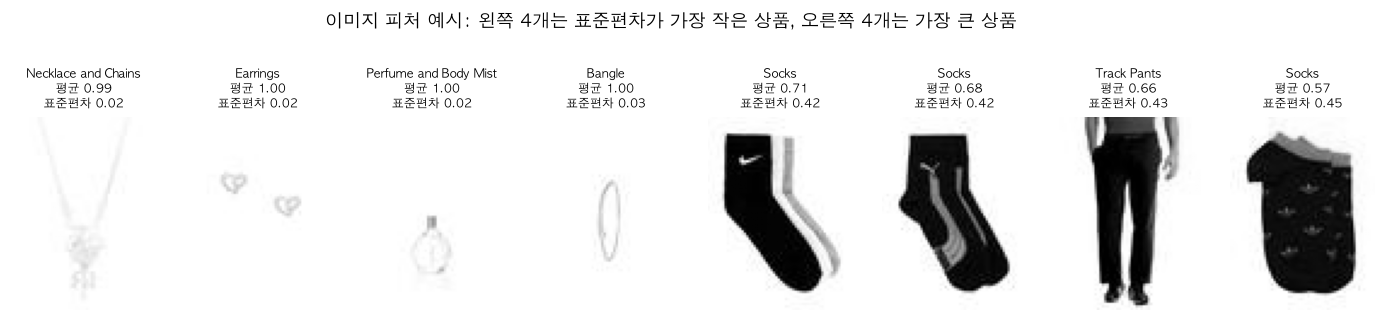

In [17]:
order = pr.df["img_std"].argsort().to_numpy()
picks = np.r_[order[:4], order[-4:]]
fig, axes = plt.subplots(1, 8, figsize=(16, 3.8))
for ax, i in zip(axes, picks):
    ax.imshow(images[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{pr.df['articleType'].iat[i]}\n평균 {pr.df['img_mean'].iat[i]:.2f}\n표준편차 {pr.df['img_std'].iat[i]:.2f}", fontsize=8)
    ax.axis("off")
fig.suptitle("이미지 피처 예시: 왼쪽 4개는 표준편차가 가장 작은 상품, 오른쪽 4개는 가장 큰 상품")
save_figure(fig, "image_feature_examples")
plt.show()

### 3-2. 텍스트: 상품명 단어 수와 글자 수

In [18]:
pr.add_text_features("productDisplayName", prefix="name")
sa.add_text_features("Description", prefix="desc")
print(pr.df[["name_word_count", "name_char_length"]].describe().loc[["mean", "50%", "min", "max"]])
print(sa.df[["desc_word_count", "desc_char_length"]].describe().loc[["mean", "50%", "min", "max"]])

      name_word_count  name_char_length
mean             5.73             34.35
50%              6.00             34.00
min              1.00             14.00
max             12.00             74.00
      desc_word_count  desc_char_length
mean             4.39             26.51
50%              4.00             27.00
min              1.00              6.00
max              8.00             35.00


**해석**

- 2,000장을 (80, 60) 흑백 배열로 쌓아 `images.mean(axis=(1, 2))`처럼 **축을 지정한 배열 연산 한 번**으로 평균과 표준편차를 구했다. 같은 값을 반복문으로 구한 결과와의 최대 차이는 0.0이다.
- 이미지 평균은 평균 0.84로 대부분 밝다. 상품 사진이 **흰 배경**으로 찍혀 있기 때문이다. 표준편차가 가장 작은 상품(0.02)은 흰 배경 위의 작은 목걸이·귀걸이·향수였고, 가장 큰 상품(0.42~0.45)은 검은 양말·바지처럼 흰 배경과 대비가 큰 어두운 상품이었다.
- 상품명은 평균 5.73단어(1~12단어), 거래 데이터의 상품명은 평균 4.39단어다.
- 시사점: 이 이미지 피처는 "상품이 얼마나 어둡고 화면을 얼마나 채우는가"를 수치로 나타낸다. 색상(`baseColour`)이나 카테고리를 예측하는 모델의 입력으로 쓸 수 있다.

## 4. 이상치 탐지와 처리 (IQR)

IQR(사분범위) = Q3 − Q1. 경계 [Q1 − 1.5 × IQR, Q3 + 1.5 × IQR] 밖을 이상치로 본다. 탐지 로직은 `DataAnalyzer.detect_outliers()`에 직접 구현했다.

In [19]:
rows = []
for col in ["Quantity", "Price", "amount"]:
    b = sa.iqr_bounds(col, threshold=1.5)
    n = len(sa.detect_outliers(col, threshold=1.5))
    rows.append({"컬럼": col, "Q1": b["q1"], "Q3": b["q3"], "IQR": b["iqr"], "하한": b["lower"],
                 "상한": b["upper"], "이상치 수": n, "이상치 비율(%)": n / len(sa.df) * 100})
outlier_table = pd.DataFrame(rows)
outlier_table

,컬럼,Q1,Q3,IQR,하한,상한,이상치 수,이상치 비율(%)
0,Quantity,1.00,10.00,9.00,-12.50,23.50,111341,10.69
1,Price,1.25,4.13,2.88,-3.07,8.45,81633,7.84
2,amount,3.90,17.70,13.80,-16.80,38.40,85726,8.23


In [20]:
# 3 × IQR로 기준을 넓히면 얼마나 남는지도 본다
for col in ["Quantity", "Price", "amount"]:
    print(f"{col}: 1.5×IQR {len(sa.detect_outliers(col, 1.5)):,}행, 3×IQR {len(sa.detect_outliers(col, 3)):,}행")
top = sa.detect_outliers("amount", 3).nlargest(5, "amount")[["Invoice", "Description", "Quantity", "Price", "amount", "Customer ID"]]
top

Quantity: 1.5×IQR 111,341행, 3×IQR 40,863행
Price: 1.5×IQR 81,633행, 3×IQR 24,834행


amount: 1.5×IQR 85,726행, 3×IQR 54,871행


,Invoice,Description,Quantity,Price,amount,Customer ID
1065882,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"168,469.60",16446
587080,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"77,183.60",12346
748132,556444,PICNIC BASKET WICKER 60 PIECES,60,649.50,"38,970.00",15098
241827,512771,Manual,1,"25,111.09","25,111.09",<NA>
432176,530715,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,"15,818.40",15838


treat_outliers(amount, threshold=1.5, clip): 85,726행 (경계 -16.80 ~ 38.40)


[저장] outputs/outlier_before_after.png


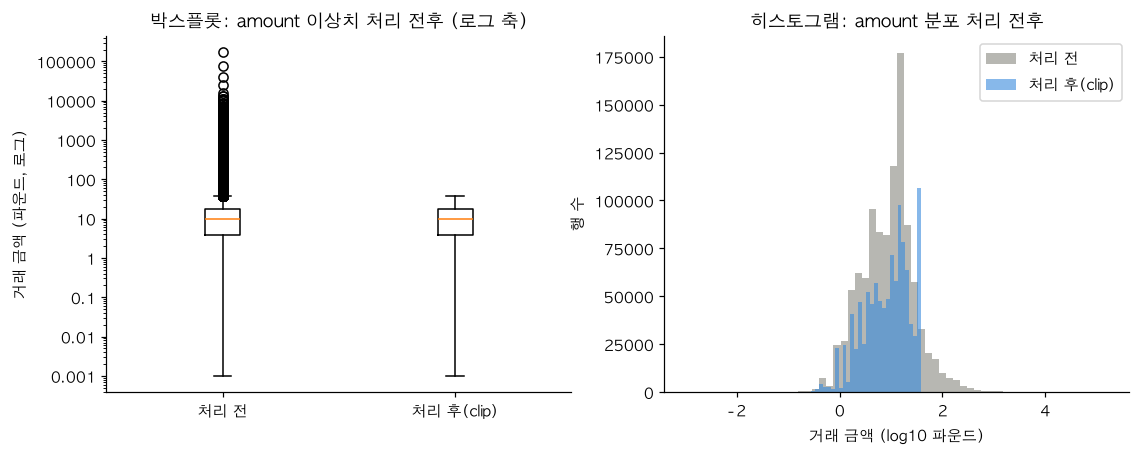

In [21]:
# 처리: 분포 분석용 사본에서 amount를 IQR 경계로 잘라 붙인다(clip). 행은 지우지 않는다.
# RFM의 Monetary는 실제 구매 금액이어야 하므로 원래 amount를 쓴다.
clipped = DataAnalyzer(df=sa.df[["amount", "Quantity", "Price"]])
n_clip = clipped.treat_outliers("amount", threshold=1.5, method="clip")
print(clipped.log[-1])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].boxplot([sa.df["amount"], clipped.df["amount"]], tick_labels=["처리 전", "처리 후(clip)"], showfliers=True)
axes[0].set_yscale("log")
plain_log_ticks(axes[0], "y")
axes[0].set(title="박스플롯: amount 이상치 처리 전후 (로그 축)", ylabel="거래 금액 (파운드, 로그)")
axes[1].hist(np.log10(sa.df["amount"]), bins=60, color=GRAY, alpha=0.6, label="처리 전")
axes[1].hist(np.log10(clipped.df["amount"]), bins=60, color=BLUE, alpha=0.6, label="처리 후(clip)")
axes[1].set(title="히스토그램: amount 분포 처리 전후", xlabel="거래 금액 (log10 파운드)", ylabel="행 수")
axes[1].legend()
save_figure(fig, "outlier_before_after")
plt.show()

**해석**

- 1.5 × IQR 기준이면 `Quantity`의 10.69%, `Price`의 7.84%, `amount`의 8.23%가 이상치다. 기준을 3 × IQR로 넓혀도 `amount`는 54,871행(5.3%)이 남는다.
- 금액 상위 이상치는 80,995개(168,469.60파운드), 74,215개 주문처럼 **실제 도매 대량 주문**이 대부분이다. 다만 `Manual`(수동 조정, 25,111.09파운드)처럼 상품이 아닌 기록도 섞여 있다.
- 이 쇼핑몰은 도매 고객이 많아 금액 분포가 원래 오른쪽으로 길다. 그래서 이상치를 지우면 실제 VIP 매출을 지우게 된다. 그래서 **분포를 보는 사본에서만 경계값(38.40파운드)으로 잘라 붙이고(clip)**, RFM의 금액은 원래 값을 쓴다. 박스플롯에서 처리 후 수염 밖의 점이 사라지고, 히스토그램에서 경계값 위치에 잘린 값이 모인 것이 보인다.
- 시사점: IQR 이상치는 "오류"가 아니라 "드문 값"이라는 뜻이다. 지울지, 자를지, 둘지는 분석 목적에 따라 정해야 한다.

## 5. 통계 분석

### 5-1. 요약 통계

In [22]:
sa.summary_stats(["Quantity", "Price", "amount"])

,평균,중앙값,표준편차,Q1(25%),Q3(75%),최솟값,최댓값
Quantity,10.96,3.00,126.51,1.00,10.00,1.00,"80,995.00"
Price,4.08,2.10,51.45,1.25,4.13,0.00,"25,111.09"
amount,20.13,9.96,203.12,3.90,17.70,0.00,"168,469.60"


In [23]:
pr.summary_stats(["img_mean", "img_std", "name_word_count", "year"])

,평균,중앙값,표준편차,Q1(25%),Q3(75%),최솟값,최댓값
img_mean,0.84,0.84,0.09,0.78,0.90,0.42,1.00
img_std,0.25,0.26,0.08,0.19,0.31,0.02,0.45
name_word_count,5.73,6.00,1.37,5.00,7.00,1.00,12.00
year,"2,012.71","2,012.00",2.07,"2,011.00","2,015.00","2,010.00","2,018.00"


[저장] outputs/histograms.png


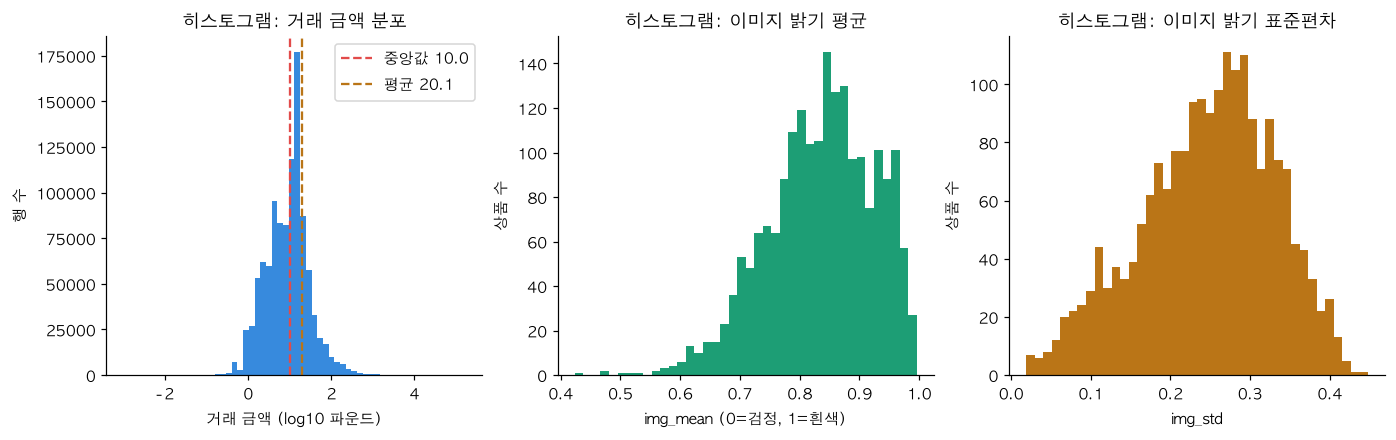

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(np.log10(sa.df["amount"]), bins=60, color=BLUE)
axes[0].axvline(np.log10(sa.df["amount"].median()), color=RED, ls="--", label=f"중앙값 {sa.df['amount'].median():.1f}")
axes[0].axvline(np.log10(sa.df["amount"].mean()), color=ORANGE, ls="--", label=f"평균 {sa.df['amount'].mean():.1f}")
axes[0].set(title="히스토그램: 거래 금액 분포", xlabel="거래 금액 (log10 파운드)", ylabel="행 수")
axes[0].legend()
axes[1].hist(pr.df["img_mean"], bins=40, color=GREEN)
axes[1].set(title="히스토그램: 이미지 밝기 평균", xlabel="img_mean (0=검정, 1=흰색)", ylabel="상품 수")
axes[2].hist(pr.df["img_std"], bins=40, color=ORANGE)
axes[2].set(title="히스토그램: 이미지 밝기 표준편차", xlabel="img_std", ylabel="상품 수")
save_figure(fig, "histograms")
plt.show()

**해석**

- 판매 데이터에서 `amount`(거래 금액)는 평균 20.13파운드, 중앙값 9.96파운드, 표준편차 203.12파운드다. 평균이 중앙값의 2배이고 표준편차가 평균의 10배다. **한 줄짜리 거래는 대부분 10파운드 안팎**이고, 아주 큰 거래 몇 건이 평균을 끌어올린다. `Price`도 평균 4.08, 중앙값 2.10으로 같은 모양이다.
- 사분위수로 보면 거래 금액의 가운데 50%는 3.90~17.70파운드 사이다.
- 상품 이미지 평균은 Q1 0.78 ~ Q3 0.90에 몰려 있고, 표준편차는 0.19 ~ 0.31 사이다.
- 시사점: 이 데이터에서 "평균 주문 금액"을 목표 지표로 쓰면 소수 도매 주문에 크게 흔들린다. 중앙값이나 로그 스케일 지표를 함께 봐야 한다.

### 5-2. 월별 매출 추이

[저장] outputs/monthly_revenue.png


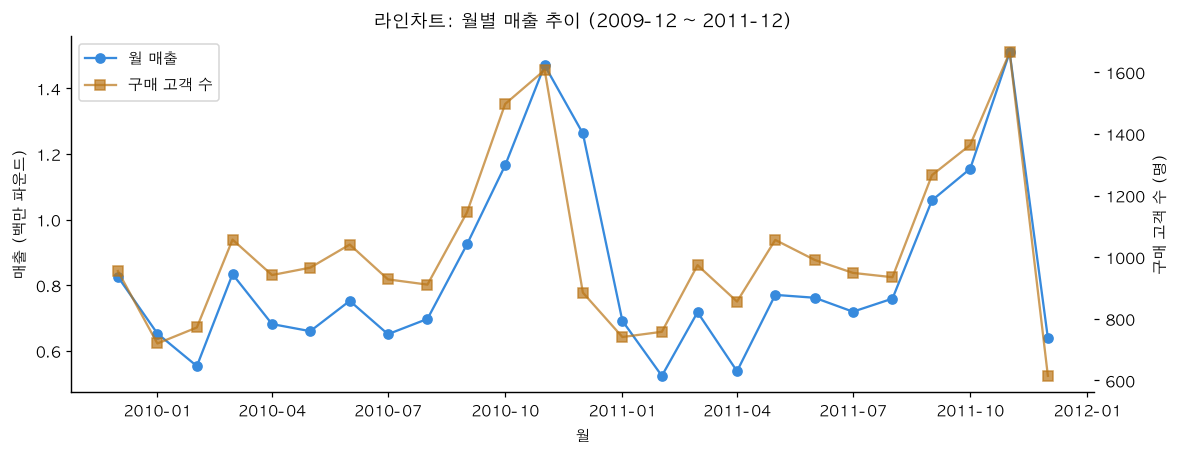

마지막 달은 2011-12-09까지만 있어 일부 기간이다.
InvoiceDate
2009-12-01   0.83
2010-01-01   0.65
2010-02-01   0.55
2010-03-01   0.83
2010-04-01   0.68
2010-05-01   0.66
2010-06-01   0.75
2010-07-01   0.65
2010-08-01   0.70
2010-09-01   0.92
2010-10-01   1.17
2010-11-01   1.47
2010-12-01   1.26
2011-01-01   0.69
2011-02-01   0.52
2011-03-01   0.72
2011-04-01   0.54
2011-05-01   0.77
2011-06-01   0.76
2011-07-01   0.72
2011-08-01   0.76
2011-09-01   1.06
2011-10-01   1.16
2011-11-01   1.51
2011-12-01   0.64
Freq: MS


In [25]:
monthly = sa.df.set_index("InvoiceDate")["amount"].resample("MS").sum()
monthly_cust = sa.df.dropna(subset=["Customer ID"]).set_index("InvoiceDate")["Customer ID"].resample("MS").nunique()
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(monthly.index, monthly / 1e6, marker="o", color=BLUE, label="월 매출")
ax.set(title="라인차트: 월별 매출 추이 (2009-12 ~ 2011-12)", xlabel="월", ylabel="매출 (백만 파운드)")
ax2 = ax.twinx()
ax2.plot(monthly_cust.index, monthly_cust, marker="s", color=ORANGE, alpha=0.7, label="구매 고객 수")
ax2.set_ylabel("구매 고객 수 (명)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left")
save_figure(fig, "monthly_revenue")
plt.show()
print("마지막 달은 2011-12-09까지만 있어 일부 기간이다.")
print((monthly / 1e6).round(3).to_string())

**해석**

- 월 매출은 2010년 11월 147만 파운드, 2011년 11월 151만 파운드로 **두 해 모두 11월이 최고**다. 2011년 11월 매출은 같은 해 2월(52만 파운드)의 2.88배이고, 2011년 1~11월 매출 중 9~11월이 40.4%를 차지한다.
- 구매 고객 수도 매출과 같은 모양으로 오르내린다. 매출이 늘어난 이유가 주문 크기보다 **고객 수 증가**에 있다는 뜻이다.
- 2011년 12월은 9일까지만 있어 낮게 보이는 것이다.
- 시사점: 크리스마스 선물용품을 파는 회사라 매출이 9~11월에 몰린다. 재고와 마케팅은 9월 이전에 준비해야 한다.

## 6. RFM 기반 고객 세분화

- **Recency**: 기준일(마지막 거래일 다음 날) − 고객의 마지막 구매일 (일)
- **Frequency**: 서로 다른 주문(Invoice) 수
- **Monetary**: 순 구매 금액 = 구매 금액 − 취소 금액. 취소 주문(Invoice가 C로 시작)은 Recency·Frequency 계산에서는 빼고, 금액에서는 뺀다. 순 구매 금액이 0 이하인 고객(취소가 구매보다 많은 고객)은 제외한다.

각 값을 고객 순위로 5등분해 1~5점을 준다(Recency는 최근일수록 5점). 세그먼트 규칙은 위에서부터 먼저 맞는 것을 적용한다.

| 세그먼트 | 규칙 | 뜻 |
|---|---|---|
| VIP | R ≥ 4, F ≥ 4, M ≥ 4 | 최근에, 자주, 많이 산다 |
| Loyal | R ≥ 3, F ≥ 3 | 꾸준히 산다 |
| New | R ≥ 4, F ≤ 2 | 최근에 처음(또는 두 번째)으로 샀다 |
| At Risk | R ≤ 2, F ≥ 3 | 자주 샀지만 한동안 안 온다 |
| Churned | R ≤ 2, F ≤ 2 | 오래전에 조금 사고 떠났다 |
| Potential | 나머지 | 중간 고객 |

In [26]:
ra = DataAnalyzer(df=rfm_base)
rfm = ra.calculate_rfm("Customer ID", "InvoiceDate", "amount", invoice_col="Invoice", cancel_prefix="C")
print(ra.log[-1])

# 취소를 빼지 않았다면 얼마나 달라지는지: 취소 영향이 가장 큰 고객 5명
gross = sa.df.dropna(subset=["Customer ID"]).groupby("Customer ID")["amount"].sum()
cmp = pd.DataFrame({"취소 무시 금액": gross.reindex(rfm.index), "순 구매 금액": rfm["Monetary"]})
cmp["차이"] = cmp["취소 무시 금액"] - cmp["순 구매 금액"]
print(f"취소로 금액이 줄어든 고객: {(cmp['차이'] > 0.005).sum():,}명")
cmp.nlargest(5, "차이")
rfm.head()

calculate_rfm: 고객 5,842명, 기준일 2011-12-10, 순 구매 금액 0 이하 36명 제외


취소로 금액이 줄어든 고객: 2,475명


,Recency,Frequency,Monetary,R,F,M,RFM_score,segment
Customer ID,,,,,,,,
12347,2,8,"5,633.32",5,4,5,14,VIP
12348,75,5,"2,019.40",3,4,4,11,Loyal
12349,18,4,"4,404.54",5,3,5,13,Loyal
12350,310,1,334.40,2,1,2,5,Churned
12351,375,1,300.93,2,1,2,5,Churned


In [27]:
rfm[["Recency", "Frequency", "Monetary"]].describe()

,Recency,Frequency,Monetary
count,"5,842.00","5,842.00","5,842.00"
mean,199.60,6.32,"2,865.87"
std,208.77,13.04,"14,079.27"
min,0.00,1.00,0.00
25%,25.00,1.00,340.59
50%,94.00,3.00,876.87
75%,379.00,7.00,"2,235.22"
max,738.00,398.00,"598,215.22"


In [28]:
seg_order = ["VIP", "Loyal", "Potential", "New", "At Risk", "Churned"]
seg = (rfm.groupby("segment")
       .agg(고객수=("Recency", "size"), 평균_Recency=("Recency", "mean"), 평균_Frequency=("Frequency", "mean"),
            평균_Monetary=("Monetary", "mean"), 중앙_Monetary=("Monetary", "median"), 매출합=("Monetary", "sum"))
       .reindex(seg_order))
seg["고객비중(%)"] = seg["고객수"] / seg["고객수"].sum() * 100
seg["매출비중(%)"] = seg["매출합"] / seg["매출합"].sum() * 100
seg

,고객수,평균_Recency,평균_Frequency,평균_Monetary,중앙_Monetary,매출합,고객비중(%),매출비중(%)
segment,,,,,,,,
VIP,1283,18.99,17.16,"9,056.95","3,946.12","11,620,071.05",21.96,69.40
Loyal,1404,70.12,5.50,"1,880.14","1,092.49","2,639,723.48",24.03,15.77
Potential,376,104.31,1.36,529.20,362.68,"198,980.44",6.44,1.19
New,442,27.29,1.47,507.79,366.96,"224,445.38",7.57,1.34
At Risk,818,364.74,5.00,"1,748.93","1,033.43","1,430,624.61",14.00,8.54
Churned,1519,456.63,1.26,413.82,271.85,"628,585.65",26.00,3.75


[저장] outputs/rfm_segments_bar.png


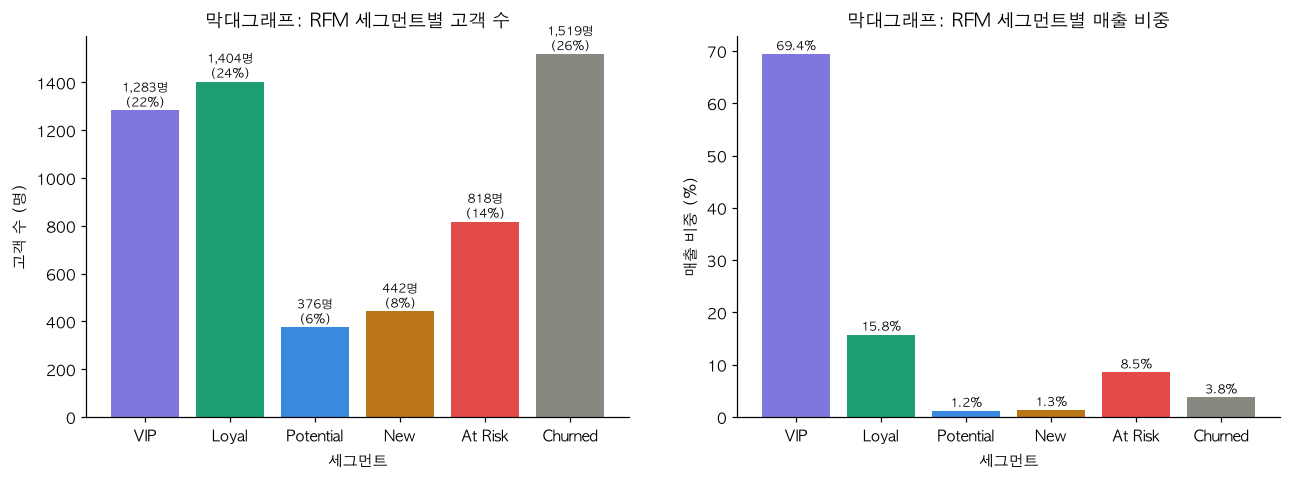

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
colors = [SEGMENT_COLORS[s] for s in seg_order]
bars = axes[0].bar(seg_order, seg["고객수"], color=colors)
axes[0].bar_label(bars, labels=[f"{n:,}명\n({p:.0f}%)" for n, p in zip(seg["고객수"], seg["고객비중(%)"])], fontsize=8)
axes[0].set(title="막대그래프: RFM 세그먼트별 고객 수", xlabel="세그먼트", ylabel="고객 수 (명)")
bars = axes[1].bar(seg_order, seg["매출비중(%)"], color=colors)
axes[1].bar_label(bars, fmt="%.1f%%", fontsize=8)
axes[1].set(title="막대그래프: RFM 세그먼트별 매출 비중", xlabel="세그먼트", ylabel="매출 비중 (%)")
save_figure(fig, "rfm_segments_bar")
plt.show()

[저장] outputs/rfm_heatmap_scatter.png


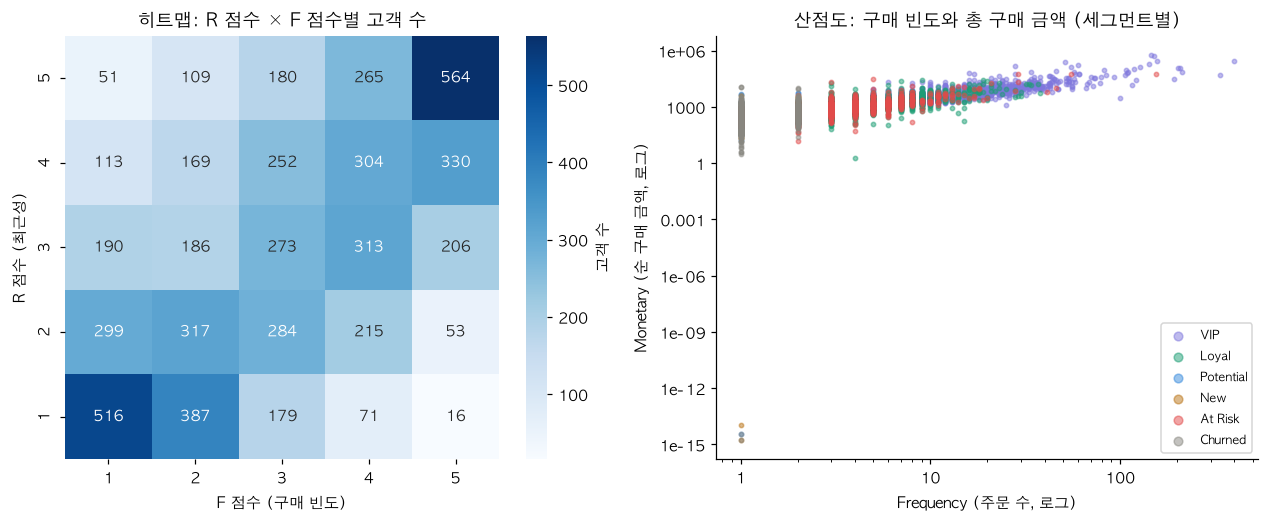

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
counts = pd.crosstab(rfm["R"], rfm["F"]).sort_index(ascending=False)
sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", ax=axes[0], cbar_kws={"label": "고객 수"})
axes[0].set(title="히트맵: R 점수 × F 점수별 고객 수", xlabel="F 점수 (구매 빈도)", ylabel="R 점수 (최근성)")
for s in seg_order:
    m = rfm["segment"] == s
    axes[1].scatter(rfm.loc[m, "Frequency"], rfm.loc[m, "Monetary"], s=8, alpha=0.5, color=SEGMENT_COLORS[s], label=s)
axes[1].set(xscale="log", yscale="log", title="산점도: 구매 빈도와 총 구매 금액 (세그먼트별)",
            xlabel="Frequency (주문 수, 로그)", ylabel="Monetary (순 구매 금액, 로그)")
plain_log_ticks(axes[1], "x"); plain_log_ticks(axes[1], "y")
axes[1].legend(markerscale=2, fontsize=8)
save_figure(fig, "rfm_heatmap_scatter")
plt.show()

**해석**

- 고객 5,842명을 6개 세그먼트로 나눴다(순 구매 금액이 0 이하인 36명 제외). 취소를 반영하지 않았다면 2,475명의 금액이 부풀려졌을 것이다. 예를 들어 80,995개를 주문했다가 전부 취소한 고객은 VIP처럼 보였을 것이다.
- **VIP 1,283명(22.0%)이 매출의 69.4%**를 낸다. 평균 19일 전에 마지막으로 샀고, 2년간 평균 17.2번 주문했다.
- **At Risk 818명(14.0%)**은 평균 5.0번 주문한 단골이었지만, 평균 365일 동안 오지 않았다. 매출의 8.5%다.
- Churned 1,519명(26.0%)은 고객 수로는 가장 많지만 매출은 3.8%다.
- R × F 히트맵에서 고객이 대각선 양 끝(R5·F5 566명, R1·F1 514명)에 몰린다. 최근에 온 고객이 자주 오는 고객이기도 하다는 뜻이다.
- 산점도에서 VIP(보라)는 오른쪽 위, Churned(회색)는 왼쪽 아래에 모인다. 주문이 늘수록 금액도 함께 늘어나는 모양이다.

## 7. 상관 분석

In [31]:
ca = DataAnalyzer(df=rfm)
corr_rfm = pd.concat([ca.correlations([("Frequency", "Monetary"), ("Recency", "Frequency"), ("Recency", "Monetary")], "pearson"),
                      ca.correlations([("Frequency", "Monetary"), ("Recency", "Frequency"), ("Recency", "Monetary")], "spearman").iloc[:, 2]], axis=1)
corr_rfm

,변수1,변수2,상관계수(pearson),상관계수(spearman)
0,Frequency,Monetary,0.63,0.86
1,Recency,Frequency,-0.26,-0.56
2,Recency,Monetary,-0.13,-0.52


In [32]:
corr_tx = pd.concat([sa.correlations([("Quantity", "Price")], "pearson"),
                     sa.correlations([("Quantity", "Price")], "spearman").iloc[:, 2]], axis=1)
corr_pr = pd.concat([pr.correlations([("img_mean", "img_std"), ("name_word_count", "img_std"), ("year", "img_mean")], "pearson"),
                     pr.correlations([("img_mean", "img_std"), ("name_word_count", "img_std"), ("year", "img_mean")], "spearman").iloc[:, 2]], axis=1)
pd.concat([corr_tx, corr_pr], ignore_index=True)

,변수1,변수2,상관계수(pearson),상관계수(spearman)
0,Quantity,Price,-0.00,-0.42
1,img_mean,img_std,-0.82,-0.84
2,name_word_count,img_std,0.02,0.03
3,year,img_mean,0.11,0.16


[저장] outputs/correlation_heatmaps.png


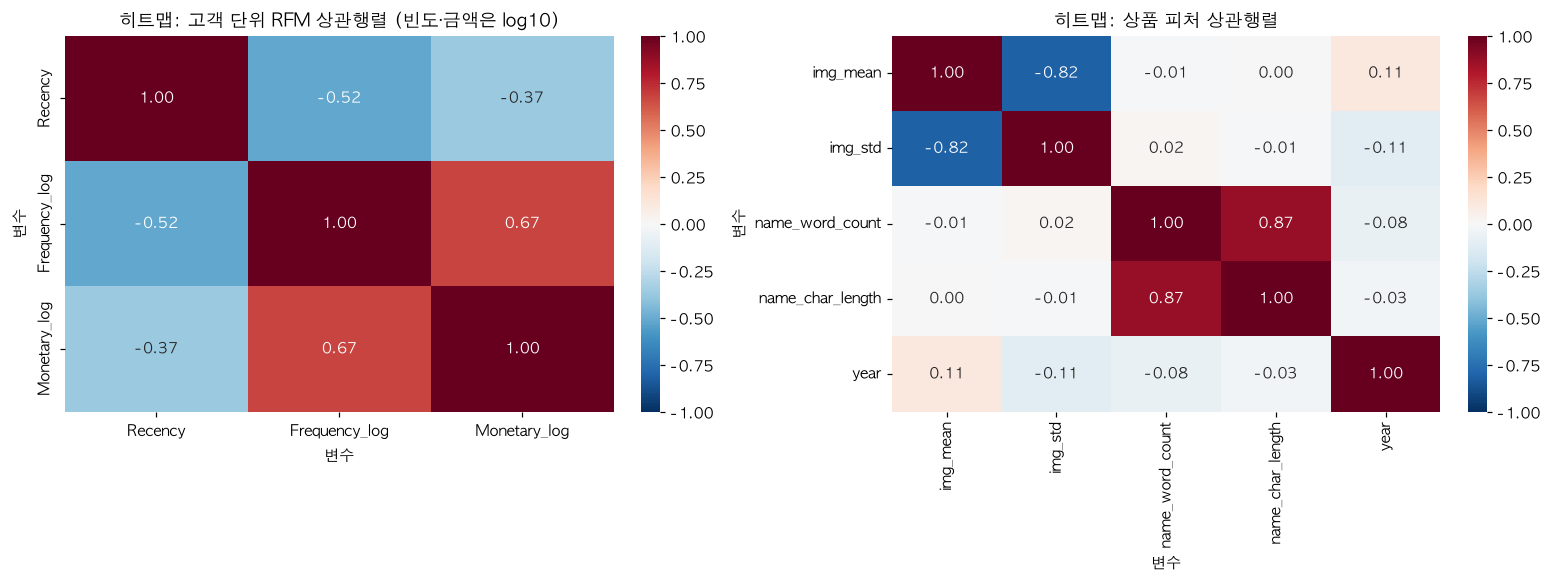

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), layout="constrained")
cust = rfm[["Recency", "Frequency", "Monetary"]].assign(Frequency_log=np.log10(rfm["Frequency"]), Monetary_log=np.log10(rfm["Monetary"]))
sns.heatmap(cust[["Recency", "Frequency_log", "Monetary_log"]].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0])
axes[0].set(title="히트맵: 고객 단위 RFM 상관행렬 (빈도·금액은 log10)", xlabel="변수", ylabel="변수")
sns.heatmap(pr.df[["img_mean", "img_std", "name_word_count", "name_char_length", "year"]].corr(), annot=True, fmt=".2f",
            cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[1])
axes[1].set(title="히트맵: 상품 피처 상관행렬", xlabel="변수", ylabel="변수")
save_figure(fig, "correlation_heatmaps")
plt.show()

[저장] outputs/product_scatter_bar.png


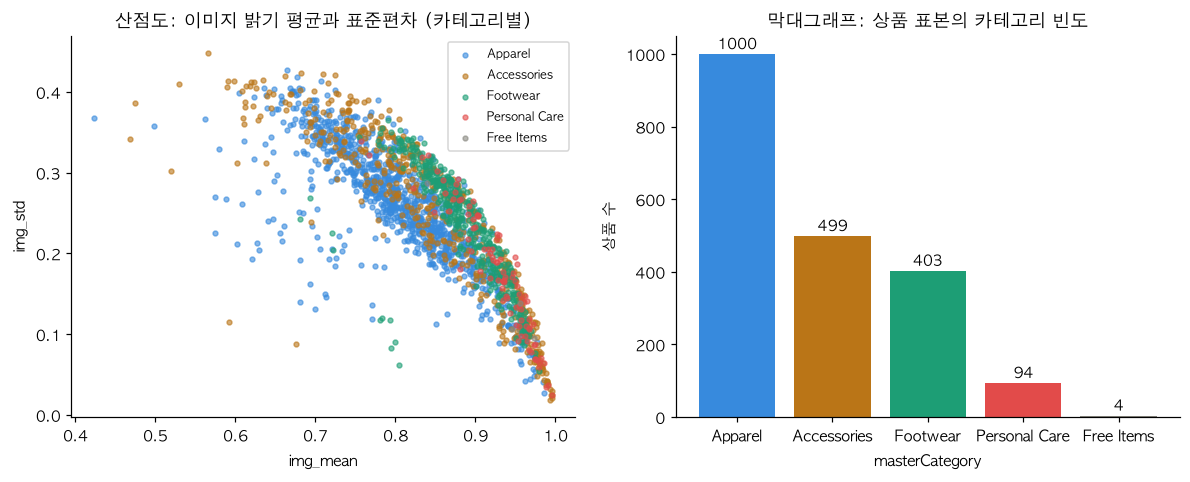

,img_mean,img_std,name_word_count
masterCategory,,,
Accessories,0.84,0.25,5.46
Apparel,0.80,0.26,5.83
Footwear,0.89,0.23,5.79
Free Items,0.93,0.16,5.25
Personal Care,0.93,0.18,5.89


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cat_colors = {"Apparel": BLUE, "Accessories": ORANGE, "Footwear": GREEN, "Personal Care": RED, "Free Items": GRAY}
for c, col in cat_colors.items():
    m = pr.df["masterCategory"] == c
    axes[0].scatter(pr.df.loc[m, "img_mean"], pr.df.loc[m, "img_std"], s=10, alpha=0.6, color=col, label=c)
axes[0].set(title="산점도: 이미지 밝기 평균과 표준편차 (카테고리별)", xlabel="img_mean", ylabel="img_std")
axes[0].legend(fontsize=8)
cnt = pr.df["masterCategory"].value_counts()
bars = axes[1].bar(cnt.index, cnt.values, color=[cat_colors[c] for c in cnt.index])
axes[1].bar_label(bars)
axes[1].set(title="막대그래프: 상품 표본의 카테고리 빈도", xlabel="masterCategory", ylabel="상품 수")
save_figure(fig, "product_scatter_bar")
plt.show()
pr.df.groupby("masterCategory")[["img_mean", "img_std", "name_word_count"]].mean()

**해석**

| 변수 쌍 | Pearson | Spearman | 해석 |
|---|---|---|---|
| Frequency – Monetary | 0.63 | **0.86** | 자주 사는 고객이 많이 쓴다. 극단값의 영향을 덜 받는 순위 상관이 더 강하다 |
| Recency – Frequency | −0.26 | **−0.56** | 최근에 온 고객일수록 주문 수가 많다 |
| Quantity – Price | 0.00 | **−0.42** | 직선 관계는 없지만, 순위로 보면 싼 상품일수록 많이 산다 |
| img_mean – img_std | −0.82 | −0.84 | 밝은(흰 배경이 많은) 이미지일수록 대비가 작다 |
| name_word_count – img_std | 0.02 | 0.03 | 상품명 길이와 이미지 대비는 관계가 없다 |

- `Quantity`와 `Price`의 Pearson 상관은 0.00이지만 Spearman은 −0.42다. 소수의 극단값이 직선 관계를 가리고 있었다는 뜻이다. **꼬리가 긴 데이터에서는 Spearman도 함께 봐야 한다.**
- Spearman은 SciPy 없이 "순위로 바꾼 뒤 Pearson"으로 직접 계산했다(`DataAnalyzer.correlations`).
- 시사점: 주문 빈도와 금액이 강하게 함께 움직이므로, 구매 빈도를 늘리는 활동(재구매 알림, 정기 주문)이 매출 증대로 이어질 가능성이 크다. 다만 상관은 인과가 아니다.

## 8. 비즈니스 인사이트

같은 내용을 README.md에도 정리했다.

In [35]:
# 인사이트 근거 수치
vip, risk, churn, new = (rfm[rfm["segment"] == s] for s in ["VIP", "At Risk", "Churned", "New"])
print(f"VIP: {len(vip):,}명 ({len(vip) / len(rfm) * 100:.1f}%)이 매출의 {vip['Monetary'].sum() / rfm['Monetary'].sum() * 100:.1f}%")
print(f"At Risk: {len(risk):,}명, 평균 {risk['Recency'].mean():.0f}일 미방문, 평균 주문 {risk['Frequency'].mean():.1f}회, 매출 합 {risk['Monetary'].sum():,.0f}파운드")
print(f"New: {len(new):,}명, 평균 주문 {new['Frequency'].mean():.1f}회, 평균 금액 {new['Monetary'].mean():,.0f}파운드")
one = (rfm["Frequency"] == 1).mean() * 100
print(f"한 번만 주문한 고객 비율: {one:.1f}%")
top1 = rfm["Monetary"].nlargest(int(len(rfm) * 0.01)).sum() / rfm["Monetary"].sum() * 100
print(f"상위 1% 고객의 매출 비중: {top1:.1f}%")
q4 = monthly["2010-09":"2010-11"].sum() / monthly["2010-01":"2010-12"].sum() * 100
print(f"2010년 매출 중 9~11월 비중: {q4:.1f}%")

VIP: 1,283명 (22.0%)이 매출의 69.4%
At Risk: 818명, 평균 365일 미방문, 평균 주문 5.0회, 매출 합 1,430,625파운드
New: 442명, 평균 주문 1.5회, 평균 금액 508파운드
한 번만 주문한 고객 비율: 27.4%
상위 1% 고객의 매출 비중: 30.9%
2010년 매출 중 9~11월 비중: 34.6%


**인사이트 1. 매출의 69%가 고객 22%(VIP)에게서 나온다**

- (근거) VIP 1,283명(전체의 22.0%)이 순 매출의 69.4%(1,162만 파운드)를 냈다. 상위 1% 고객만으로도 매출의 30.9%다(세그먼트별 매출 비중 막대그래프).
- (실행) VIP 대상 → 대량 구매 할인 단가, 전담 담당자, 신상품 선공개 같은 전용 혜택 → VIP 이탈을 막는다. VIP 1명이 떠나면 평균 9,057파운드(2년 순 구매 금액)를 잃는다.
- (검증) VIP 중 도매업체와 개인 고객이 얼마나 섞여 있는지 알 수 있는 고객 유형 데이터가 추가로 필요하다. 도매업체라면 할인보다 결제 조건이나 배송 혜택이 더 효과적일 수 있다.

**인사이트 2. 단골이었다가 1년 가까이 오지 않는 At Risk 고객이 818명 있다**

- (근거) At Risk 818명(14.0%)은 2년간 평균 5.0번 주문했지만 평균 365일 동안 구매가 없다. 이 고객들의 순 구매 금액 합은 143만 파운드(매출의 8.5%)다.
- (실행) At Risk 대상 → 과거 구매 상품의 재입고·신상품 안내와 복귀 쿠폰 발송 → 이 중 10%(약 82명)만 돌아와도, 평균 순 구매 금액 1,749파운드 수준의 고객을 되찾는다.
- (검증) 반증 가능성: 도매 고객이 폐업했거나 거래처를 바꾼 것이라면 쿠폰은 효과가 없다. 이탈 사유를 알려면 고객 설문이나 경쟁사 가격 데이터가 필요하다.

**인사이트 3. 매출은 9~11월에 몰리지만, 12월 첫 구매 고객은 거의 돌아오지 않는다**

- (근거) 2011년 1~11월 매출의 40.4%가 9~11월에 나왔고, 11월 매출은 2월의 2.88배다(월별 매출 라인차트). 2010년 12월에 처음 산 고객 76명의 1~6개월 뒤 재구매율은 평균 7.9%로, 다른 달 코호트 평균 19.5%의 절반도 안 된다(보너스 2 코호트 히트맵).
- (실행) 11~12월 첫 구매 고객 대상 → 첫 구매 후 30일 안에 1월용 재구매 쿠폰과 비시즌 상품 안내 발송 → 이 코호트의 재구매율을 다른 달 수준(약 20%)으로 끌어올린다. 재고와 광고는 9월 이전에 준비한다.
- (검증) 12월 첫 구매 고객이 선물을 한 번 사는 개인 고객인지 알 수 없다. 고객 유형 데이터가 추가로 필요하다. 또 12월 코호트는 2010년 한 번만 관측했으므로(2011년 12월은 9일까지만 있음) 매년 반복되는 현상인지 다음 해 데이터로 확인해야 한다.

## 9. 보너스

### 보너스 1. 이미지 고급 피처: 밝기 히스토그램과 엣지 세기

In [36]:
hist = DataAnalyzer.image_histogram_features(images, bins=8)
pr.df["edge_strength"] = DataAnalyzer.edge_strength(images)
pr.df["dark_ratio"] = hist[:, :2].sum(axis=1)     # 밝기 0~0.25 구간 픽셀 비율
pr.df["white_ratio"] = hist[:, -1]                # 밝기 0.875~1 구간 (흰 배경)
print("히스토그램 각 행의 합 (1이어야 함):", np.unique(hist.sum(axis=1).round(6)))
pr.df.groupby("masterCategory")[["edge_strength", "dark_ratio", "white_ratio"]].mean().sort_values("edge_strength")

히스토그램 각 행의 합 (1이어야 함): [1.]


,edge_strength,dark_ratio,white_ratio
masterCategory,,,
Personal Care,0.03,0.03,0.86
Free Items,0.03,0.02,0.85
Footwear,0.04,0.06,0.79
Accessories,0.05,0.09,0.74
Apparel,0.06,0.08,0.62


[저장] outputs/bonus_image_features.png


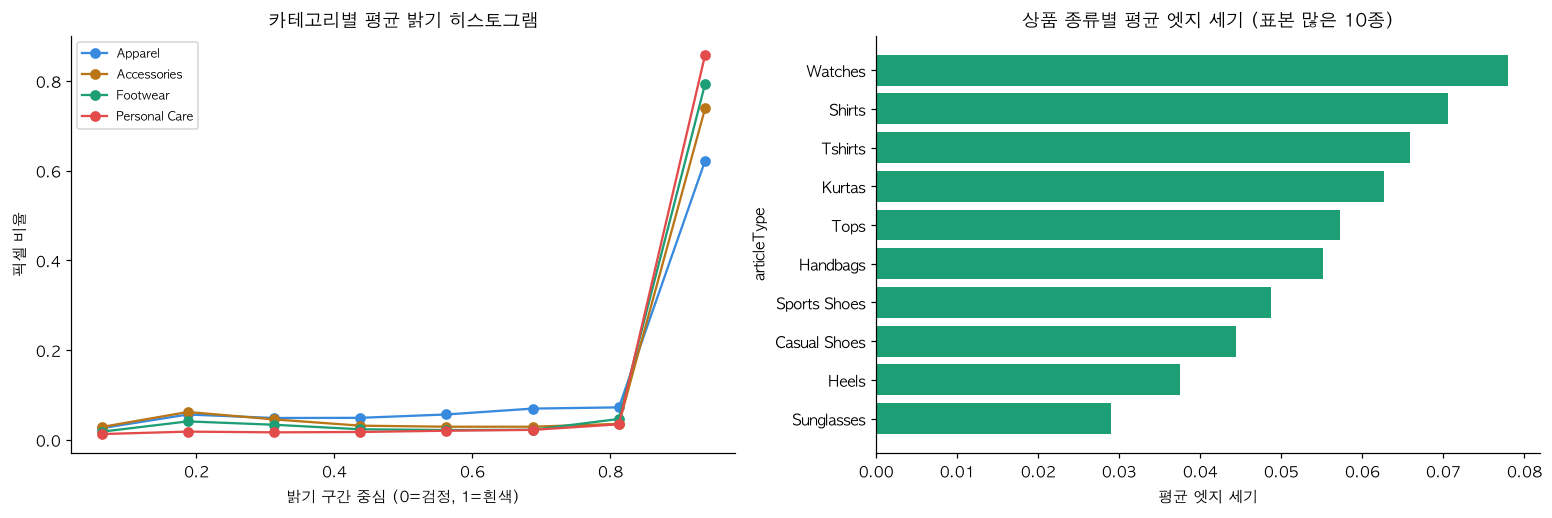

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained")
for c, col in cat_colors.items():
    m = (pr.df["masterCategory"] == c).to_numpy()
    if m.sum() >= 10:
        axes[0].plot(np.arange(8) / 8 + 1 / 16, hist[m].mean(axis=0), marker="o", color=col, label=c)
axes[0].set(title="카테고리별 평균 밝기 히스토그램", xlabel="밝기 구간 중심 (0=검정, 1=흰색)", ylabel="픽셀 비율")
axes[0].legend(fontsize=8)
order = pr.df.groupby("articleType")["edge_strength"].mean()
top_types = pr.df["articleType"].value_counts().index[:10]
order = order[top_types].sort_values()
axes[1].barh(order.index, order.values, color=GREEN)
axes[1].set(title="상품 종류별 평균 엣지 세기 (표본 많은 10종)", xlabel="평균 엣지 세기", ylabel="articleType")
save_figure(fig, "bonus_image_features")
plt.show()

**해석**

- 밝기 히스토그램(8구간)과 엣지 세기를 반복문 없이 배열 연산으로 계산했다. 히스토그램은 구간 번호를 구한 뒤 `np.bincount` 한 번으로 세고, 엣지 세기는 옆·아래 픽셀과의 밝기 차이(`np.diff`)로 구한다.
- 흰 배경 비율(`white_ratio`)은 Personal Care 0.86, Apparel 0.62다. 옷은 화면을 넓게 채우고, 향수·화장품은 작게 찍혀 배경이 많다.
- 평균 엣지 세기는 Apparel 0.06, Personal Care 0.03으로 2배 차이가 난다. 상품 종류로는 시계(Watches)와 셔츠가 높고 선글라스·힐이 낮다. 무늬, 단추, 시곗바늘처럼 **윤곽이 많은 상품일수록 엣지가 세다.**
- 시사점: 평균·표준편차만으로는 구분이 어려운 상품도 히스토그램과 엣지 피처를 더하면 카테고리 분류에 쓸 정보가 늘어난다.

### 보너스 2. 코호트 분석

데이터에 가입일이 없으므로 **고객의 첫 구매 월을 가입 월로 본다.** 재구매율 = 코호트 고객 중 k개월 뒤에도 구매한 고객의 비율.

[저장] outputs/bonus_cohort_heatmap.png


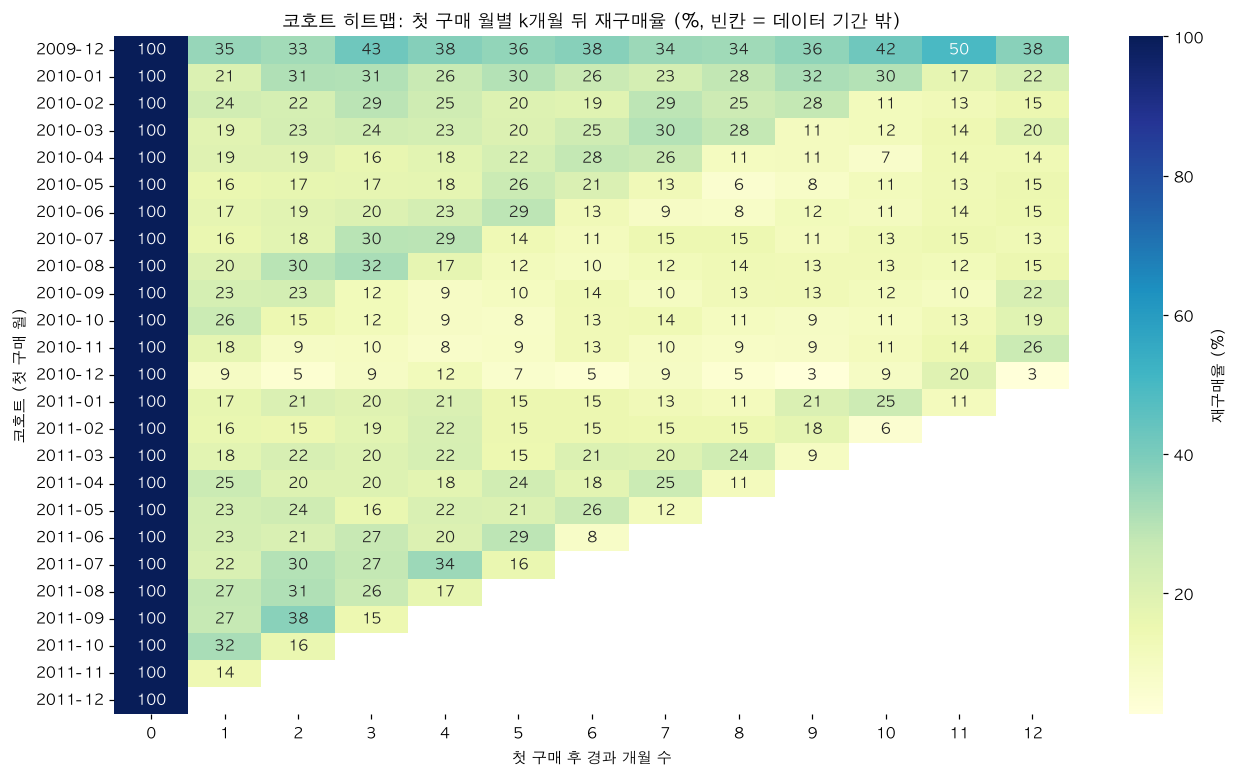

코호트 크기(명): {Period('2009-12', 'M'): 955, Period('2010-01', 'M'): 383, Period('2010-02', 'M'): 374, Period('2010-03', 'M'): 443, Period('2010-04', 'M'): 294, Period('2010-05', 'M'): 254}
1개월 뒤 재구매율 평균 (2009-12 코호트 제외): 20.6%


In [38]:
retention = sa.cohort_retention("Customer ID", "InvoiceDate")
sizes = sa.df.dropna(subset=["Customer ID"]).groupby("Customer ID")["InvoiceDate"].min().dt.to_period("M").value_counts().sort_index()
fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(retention.iloc[:, :13] * 100, annot=True, fmt=".0f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "재구매율 (%)"})
ax.set(title="코호트 히트맵: 첫 구매 월별 k개월 뒤 재구매율 (%, 빈칸 = 데이터 기간 밖)", xlabel="첫 구매 후 경과 개월 수", ylabel="코호트 (첫 구매 월)")
save_figure(fig, "bonus_cohort_heatmap")
plt.show()
print("코호트 크기(명):", sizes.head(6).to_dict())
print("1개월 뒤 재구매율 평균 (2009-12 코호트 제외):", f"{retention.iloc[1:, 1].mean() * 100:.1f}%")

**해석**

- 첫 구매 후 1~6개월 재구매율은 대부분의 코호트에서 15~30% 사이다(2010-01 ~ 2011-06 코호트 평균 19.5%, 2010-12 제외).
- **2009-12 코호트(955명)는 재구매율이 35~50%로 유독 높다.** 데이터가 2009년 12월에 시작하므로, 그 전부터 거래하던 기존 단골이 모두 "2009년 12월 첫 구매"로 잡혔기 때문이다(왼쪽 잘림). 이 코호트는 신규 고객 비교에서 빼야 한다.
- **2010-12 코호트(76명)는 1~6개월 재구매율이 평균 7.9%로 가장 낮다.** 2010-11 코호트(325명)도 10.9%로 낮다. 크리스마스 선물을 사러 한 번 온 고객이 많다는 뜻으로 보인다.
- 오른쪽 아래 빈칸은 0%가 아니라 데이터 기간(2011-12-09까지)이 끝나 아직 관측할 수 없는 칸이다.

### 보너스 3. 인터랙티브 시각화 (Plotly)

이 보너스에 한해 Plotly 사용이 허용된다. 결과는 `outputs/rfm_interactive.html`로 저장한다. 브라우저로 열면 점에 마우스를 올려 고객별 값을 볼 수 있다.

In [39]:
import plotly.express as px

plot_df = rfm.reset_index().rename(columns={"Customer ID": "customer_id"})
fig = px.scatter(plot_df, x="Frequency", y="Monetary", color="segment", size="R", log_x=True, log_y=True,
                 hover_data=["customer_id", "Recency", "Frequency", "Monetary", "R", "F", "M"],
                 category_orders={"segment": seg_order}, color_discrete_map=SEGMENT_COLORS,
                 title="RFM 세그먼트 (점 크기 = R 점수, 마우스를 올리면 고객 정보)",
                 labels={"Frequency": "구매 빈도 (주문 수)", "Monetary": "총 구매 금액 (파운드)"})
out = ROOT / "outputs" / "rfm_interactive.html"
fig.write_html(out, include_plotlyjs="cdn")
print(f"[저장] outputs/{out.name}")

[저장] outputs/rfm_interactive.html


## 10. 처리 기록

In [40]:
for name, a in [("거래", tx), ("판매", sa), ("RFM", ra), ("상품", pr)]:
    print(f"[{name}]")
    for line in a.log:
        print("  ", line)

[거래]
   load_data: 1,067,371행 × 8열
   handle_missing_values(Description, group_mode, group=StockCode): 4,019칸 채움, 363칸 남음
   handle_missing_values(Description, constant, group=None): 363칸 채움, 0칸 남음
[판매]
   add_text_features(Description) → desc_word_count, desc_char_length
[RFM]
   calculate_rfm: 고객 5,842명, 기준일 2011-12-10, 순 구매 금액 0 이하 36명 제외
[상품]
   load_data: 2,000행 × 11열
   add_image_features: 2,000장 → img_mean, img_std
   add_text_features(productDisplayName) → name_word_count, name_char_length


## 정리

| 단계 | 결과 |
|---|---|
| 데이터 | 거래 1,067,371행 × 8열, 상품 2,000개 × 11열 + 이미지 2,000장. 수치·범주·날짜·텍스트·이미지 5가지 유형 |
| 결측치 | 상품명 4,019칸 그룹별(StockCode) 최빈값 대치, 고객 번호 결측 22.8%는 RFM에서 제외 |
| 이상치 | IQR 1.5배 기준 amount 8.23%. 실제 도매 주문이 대부분이라 분포 분석용 사본만 clip |
| 피처 | 이미지 평균·표준편차(벡터 연산), 상품명 단어 수·글자 수, (보너스) 밝기 히스토그램·엣지 세기 |
| 통계 | 거래 금액 중앙값 9.96파운드, 평균 20.13파운드. Frequency–Monetary Spearman 0.86 |
| RFM | 고객 5,842명, 6개 세그먼트. VIP 22.0%가 매출 69.4% |
| 시각화 | 히스토그램, 박스플롯, 막대그래프, 히트맵, 산점도, 라인차트 (outputs/) |
| 보너스 | 이미지 고급 피처, 코호트 히트맵, Plotly 인터랙티브 차트(outputs/rfm_interactive.html) |